# RQ9: Can the day's weather be inferred from the music alone?

**Question:** Can we predict whether a day is **gloomy** (dark and wet) or **clear** (sunny and dry) using *only* its aggregated Spotify audio profile (valence, energy, danceability, acousticness, tempo)?

This is the **reverse** of RQ6. RQ6 asked how the audio profile *differs* between gloomy and clear days (and found the mean profiles almost identical). RQ9 asks the predictive question: is there enough signal in the music to recover the weather category?

This notebook is a **detailed reporting layer** over the `Workflow 9` Snakemake outputs. It reuses the workflow's own model definitions (`train_classifier._build_model`) so the analysis here matches the pipeline exactly, then digs deeper than the single summary figure the workflow produces, giving a **per-model** view (confusion matrices, ROC/AUC, cross-validation spread, and feature attribution). The tested components themselves live under `src/rq9/`.

## Method (in brief)

1. Aggregate the charts to a **daily** audio profile and label each day **gloomy**, **clear**, or **other** with the same percentile definition used by RQ6 (`utils.label_gloomy_clear`).
2. Keep only the **gloomy** and **clear** days (423 days: 240 clear, 183 gloomy) as a two-class problem; the 1403 "other" days are dropped.
3. Train and compare **logistic regression** (feature-scaled) and **random forest** using only the audio features as predictors, judged against a **majority-class baseline**.
4. Model selection uses stratified 5-fold cross-validated accuracy; the winner is evaluated once on a held-out test set.
5. Below we inspect each model in detail: confusion matrix, ROC/AUC, CV stability, and which features drive the prediction.

## How to reproduce

Run the workflow first so the inputs this notebook reads exist:

```bash
# run from the project root
snakemake --cores 1
```

This regenerates `data/spotify_weather_merged_processed_w9.csv` and `results/workflow_9/*` (metrics, model, predictions, importances, figure). Results are deterministic (fixed random seed). Then run all cells below.

## Setup: load config, data, and the workflow's models

We reuse the exact model definitions and configuration from the pipeline, then rebuild the same train/test split (same seed), so every number below is consistent with `results/workflow_9/`.

In [11]:
import importlib.util
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

SRC = Path("..") / "src"
DATA = Path("..") / "data"
RESULTS = Path("..") / "results" / "workflow_9"


def _load(path, name):
    """Import a module by file path (the 'Workflow 9' folder name has a space)."""
    spec = importlib.util.spec_from_file_location(name, str(path))
    mod = importlib.util.module_from_spec(spec)
    sys.modules[name] = mod
    spec.loader.exec_module(mod)
    return mod


train = _load(SRC / "rq9" / "train_classifier.py", "train_classifier")

cfg = yaml.safe_load((SRC / ".." / "config" / "config.yaml").read_text())["rq9"]
features = cfg["audio_features"]
model_names = cfg["models"]
seed = cfg["random_seed"]
test_size = cfg["test_size"]
cv_folds = cfg["cv_folds"]

df = pd.read_csv(DATA / "spotify_weather_merged_processed_w9.csv")
X, y = df[features], df[train.TARGET_COL]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=test_size, random_state=seed, stratify=y)
cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=seed)

# Fit each model once; reused by every cell below.
fitted = {name: train._build_model(name, seed).fit(X_tr, y_tr) for name in model_names}
print(f"{len(df)} labelled days | train {len(X_tr)} / test {len(X_te)}")
print(f"class balance (all): {y.value_counts().to_dict()}")
print(f"features: {features}")

423 labelled days | train 317 / test 106
class balance (all): {'clear': 240, 'gloomy': 183}
features: ['valence', 'energy', 'danceability', 'acousticness', 'tempo']


## Headline: how each model compares to the baseline

The metrics table is the workflow's own output. A model only means something if it clears the majority-class baseline.

,model,cv_accuracy_mean,cv_accuracy_std,test_accuracy,precision_macro,recall_macro,f1_macro
0,baseline_majority,0.5679,0.0044,0.5660,0.2830,0.5000,0.3614
1,logistic_regression,0.7256,0.0345,0.7547,0.7711,0.7326,0.7363
2,random_forest,0.7699,0.0406,0.7547,0.7519,0.7453,0.7474


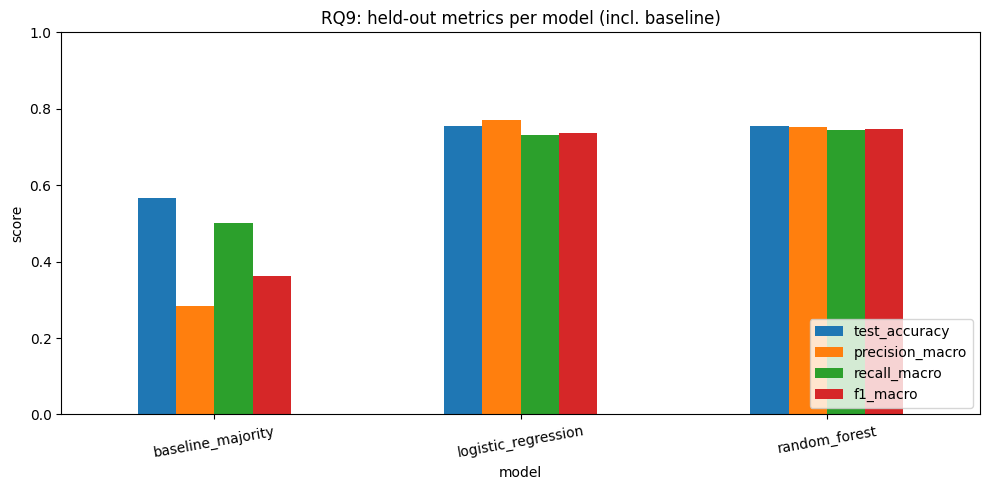

In [12]:
metrics = pd.read_csv(RESULTS / "metrics.csv")
display(metrics)

plot_cols = ["test_accuracy", "precision_macro", "recall_macro", "f1_macro"]
ax = metrics.set_index("model")[plot_cols].plot.bar(figsize=(10, 5))
ax.set_ylabel("score")
ax.set_ylim(0, 1)
ax.set_title("RQ9: held-out metrics per model (incl. baseline)")
ax.legend(loc="lower right")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

**Interpretation.** Both trained models clear the baseline on every metric: accuracy rises from 0.57 (baseline) to about 0.75, and macro F1 rises from 0.36 to about 0.74. The baseline's macro F1 is very low (0.36) because always predicting "clear" scores zero recall on gloomy days, a useful reminder that accuracy alone can hide a useless classifier. For the trained models, precision and recall stay close to each other, so neither is winning just by chasing the majority class.

## Per-model confusion matrices (held-out test)

Where does each model get it right, and which way does it lean when it is wrong?

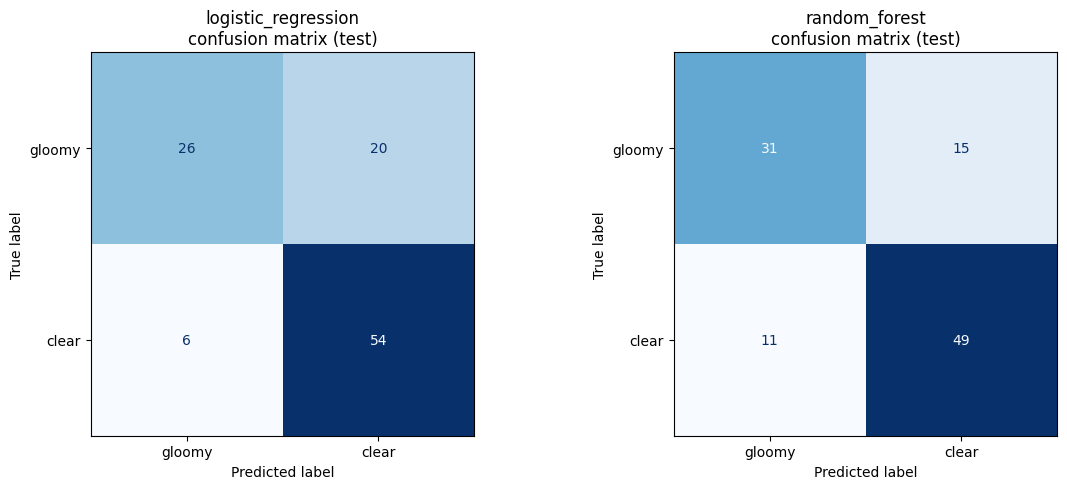

In [13]:
fig, axes = plt.subplots(1, len(model_names), figsize=(6 * len(model_names), 5))
for ax, name in zip(np.atleast_1d(axes), model_names):
    cm = confusion_matrix(y_te, fitted[name].predict(X_te), labels=train.CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=train.CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nconfusion matrix (test)")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Interpretation.** Both models identify clear days more reliably than gloomy ones. Logistic regression is the more cautious about predicting "gloomy": it labels only 26 of 46 gloomy test days correctly (20 slip through as clear), but it almost never misclassifies a clear day (54 of 60 correct). Random forest is more even-handed, catching 31 of 46 gloomy days while keeping clear accuracy high (49 of 60). The dominant error for both is the same, gloomy days mistaken for clear, which fits the season confound: a mild, upbeat winter day can look like summer to the model.

## ROC curves and AUC

Accuracy fixes a single decision threshold; the ROC curve shows how well each model *ranks* gloomy vs clear across all thresholds (AUC of 0.5 is chance).

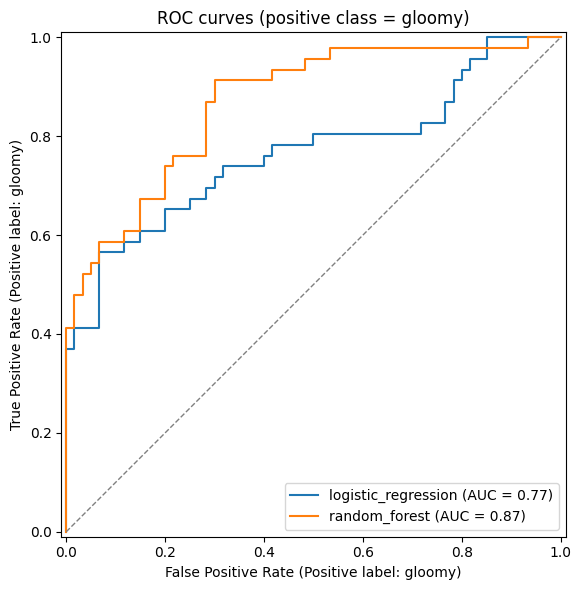

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in model_names:
    RocCurveDisplay.from_estimator(fitted[name], X_te, y_te, pos_label="gloomy", ax=ax, name=name)
ax.plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
ax.set_title("ROC curves (positive class = gloomy)")
plt.tight_layout()
plt.show()

**Interpretation.** Although both models tie at 0.755 accuracy, the ROC curves separate them. Random forest (AUC about 0.87) ranks gloomy days above clear ones far more consistently than logistic regression (AUC about 0.77) across the full range of thresholds. Accuracy only measures one cut point, whereas AUC measures the whole ranking, which is why the workflow selects random forest as the best model even though the two look identical on headline accuracy. It also means random forest would benefit more from threshold tuning if we wanted to trade some clear precision for higher gloomy recall.

## Cross-validation stability

A single test split can be lucky. The spread of per-fold accuracies shows how stable each model is, and how far both sit above the baseline.

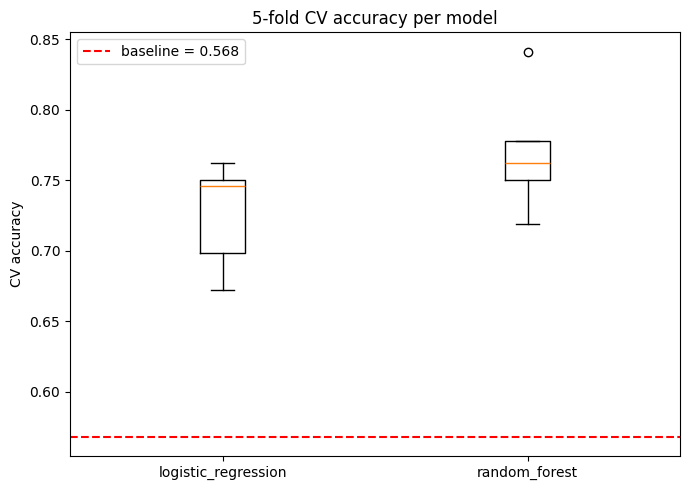

In [15]:
fold_scores = {name: cross_val_score(train._build_model(name, seed), X_tr, y_tr, cv=cv, scoring="accuracy")
               for name in model_names}
baseline_cv = metrics.loc[metrics["model"] == "baseline_majority", "cv_accuracy_mean"].iloc[0]

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([fold_scores[n] for n in model_names], tick_labels=model_names)
ax.axhline(baseline_cv, color="red", linestyle="--", label=f"baseline = {baseline_cv:.3f}")
ax.set_ylabel("CV accuracy")
ax.set_title(f"{cv_folds}-fold CV accuracy per model")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** The single test split is not a fluke. Across all five folds both models stay well above the baseline (red line near 0.57). Random forest sits a little higher and slightly tighter than logistic regression, though their spreads overlap, so the accuracy gap between the two models is modest and within normal fold-to-fold variation. The gap over the baseline, by contrast, is large and consistent, which is the result that actually matters for the research question.

## What features drive the prediction?

The two models measure importance differently (random forest by Gini impurity reduction, logistic regression by absolute feature-scaled coefficient), so we show both. Agreement between them is a good sign the signal is real.

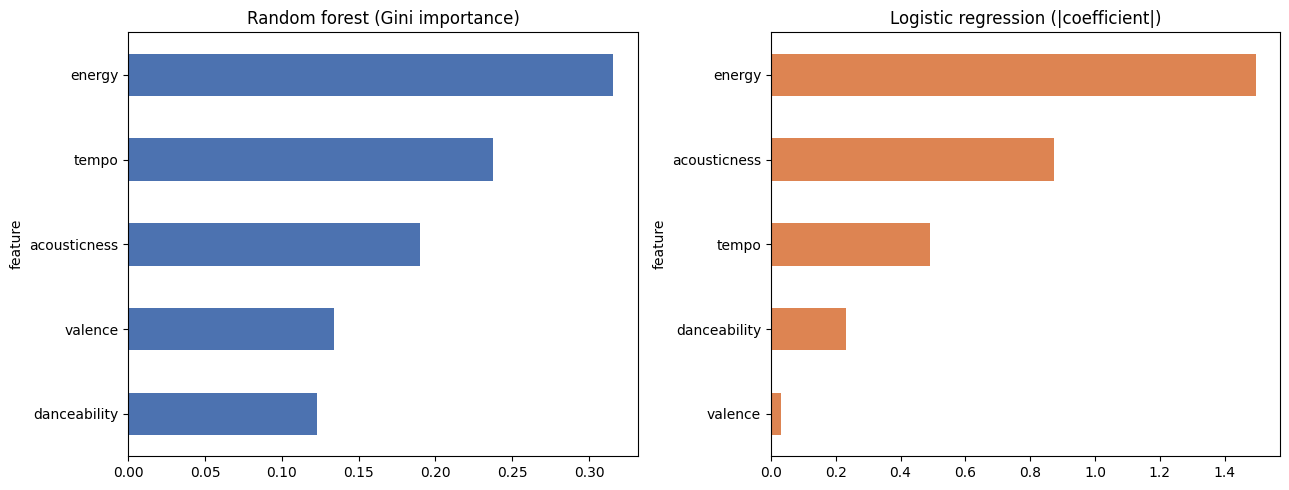

In [16]:
rf = fitted["random_forest"].named_steps["clf"]
lr = fitted["logistic_regression"].named_steps["clf"]
imp = pd.DataFrame({
    "feature": features,
    "rf_gini": rf.feature_importances_,
    "lr_abs_coef": np.abs(lr.coef_[0]),
}).set_index("feature")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
imp["rf_gini"].sort_values().plot.barh(ax=a1, color="#4C72B0")
a1.set_title("Random forest (Gini importance)")
imp["lr_abs_coef"].sort_values().plot.barh(ax=a2, color="#DD8452")
a2.set_title("Logistic regression (|coefficient|)")
plt.tight_layout()
plt.show()

**Interpretation.** Both models, using completely different importance measures, agree that energy is the strongest single predictor, followed by tempo and acousticness (the two models swap the order of those two, but both rank them just below energy). Valence (musical positivity) barely matters, which is consistent with RQ6, where valence was the one feature that did not differ significantly between gloomy and clear days. Danceability is also weak. So the signal the classifier exploits is mostly about how energetic and fast the day's music is, not how happy it sounds.

## Per-model classification reports

Precision, recall, and F1 per class, so the gloomy-vs-clear trade-off each model makes is explicit.

In [17]:
for name in model_names:
    print(f"=== {name} ===")
    print(classification_report(y_te, fitted[name].predict(X_te), digits=3))

=== logistic_regression ===
              precision    recall  f1-score   support

       clear      0.730     0.900     0.806        60
      gloomy      0.812     0.565     0.667        46

    accuracy                          0.755       106
   macro avg      0.771     0.733     0.736       106
weighted avg      0.766     0.755     0.746       106

=== random_forest ===
              precision    recall  f1-score   support

       clear      0.766     0.817     0.790        60
      gloomy      0.738     0.674     0.705        46

    accuracy                          0.755       106
   macro avg      0.752     0.745     0.747       106
weighted avg      0.754     0.755     0.753       106



**Interpretation.** The per-class numbers make the trade-off explicit. Logistic regression has high clear recall (0.90) but low gloomy recall (0.57): it is good at confirming clear days and weak at catching gloomy ones. Random forest is more balanced (clear recall 0.82, gloomy recall 0.67) and has the higher gloomy F1 (0.71 vs 0.67). If catching gloomy days were the priority, random forest would be the clearer choice; for overall accuracy the two are level.

## Caveats

- **Season confound (large, and central here).** Gloomy days are mostly winter, clear days mostly spring and summer, so the classifier is partly learning *season* from music (seasonal chart trends) rather than weather itself. "Weather from music" is, to a substantial degree, "season from music", which mirrors the RQ8 result that weather adds little beyond season.
- **Extremes only.** Only the gloomy and clear tails are classified; the 1403 "other" days are excluded. This is not a general all-weather classifier.
- **Modest sample.** 423 labelled days (106 in the test set), so the single held-out accuracy carries real uncertainty, which is exactly why cross-validation is reported alongside it.
- **Definition.** Gloomy and clear use percentile cut-points (sun at or below P25 and precip at or above P75; sun at or above P75 and precip at or below P25), the same as RQ6.

## Takeaway

The day's weather **category** can be recovered from the aggregated audio profile at about 76% accuracy (AUC near 0.87 for the best model), far above the 57% baseline, driven mainly by **energy** and **tempo**. But because gloomy days are mostly winter and clear days mostly summer, this is best read as *music encodes season, and season correlates with weather*, rather than a direct music-to-weather signal. Read together, RQ6 and RQ9 agree: weather leaves only a **faint, largely seasonal** fingerprint on what Germany streams, too small to see in the means, but just enough for a classifier to exploit.